# Notebook 04: Biểu diễn Quan hệ Tương quan và Khoảng cách Mantegna

- **Mục tiêu:** Xây dựng không gian khoảng cách mêtric dựa trên tương quan đồng biến động giá giữa 98 cổ phiếu VN100.
- **Dữ liệu vào:** Ma trận lợi suất logarit `data/processed/log_returns.csv` ($1.186 \text{ phiên} \times 98 \text{ mã}$).
- **Dữ liệu ra:** Ma trận tương quan `correlation_matrix.csv` ($98 \times 98$) và ma trận khoảng cách Mantegna `mantegna_distance_matrix.csv` ($98 \times 98$).

### Các bước thực hiện:
1. **Phân tích hạn chế của khoảng cách Euclid:** Chỉ ra các trường hợp sai lệch khi gom cụm trực tiếp chuỗi lợi suất.
2. **Tính toán ma trận tương quan Pearson ($\rho \in [-1, 1]$):** Đo lường mức độ đồng pha tuyến tính.
3. **Chuyển đổi sang khoảng cách Mantegna ($d = \sqrt{2(1 - \rho)}$):** Thiết lập không gian mêtric chuẩn trong đoạn $[0, 2]$.
4. **Kiểm tra 4 tiên đề mêtric:** Kiểm chứng thực nghiệm bất đẳng thức tam giác trên 20.000 bộ ba cổ phiếu.
5. **Khảo sát các cặp cổ phiếu tiêu biểu:** Xác định các cặp đồng pha nhất (cùng cụm) và độc lập nhất (tối ưu đa dạng hóa).

In [1]:
# 1. Khai báo các thư viện khoa học dữ liệu và trực quan hóa
import sys
import os
from pathlib import Path

# Thiết lập đường dẫn thư mục gốc dự án linh hoạt
curr_dir = Path(".").resolve()
if (curr_dir / "data").exists():
    PROJECT_ROOT = curr_dir
elif (curr_dir.parent / "data").exists():
    PROJECT_ROOT = curr_dir.parent
else:
    PROJECT_ROOT = Path(r"d:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cấu hình phong cách đồ thị chuẩn ấn bản khoa học
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

print("Đã nạp thành công các thư viện cần thiết!")


Đã nạp thành công các thư viện cần thiết!


### 1. Hạn chế của Khoảng cách Euclid trên Chuỗi Lợi suất
- Khoảng cách Euclid hình học: $d_{Euclid}(\mathbf{r}_i, \mathbf{r}_j) = \sqrt{\sum_{t=1}^T (r_{i, t} - r_{j, t})^2}$.
- **Hai sai lầm cốt lõi khi áp dụng vào tài chính:**
  1. *Bẫy biên độ dao động (Scale bias):* Hai cổ phiếu đồng pha 100% nhưng một mã dao động $\pm 7\%$ và một mã phòng thủ $\pm 1\%$ sẽ bị Euclid tính khoảng cách lớn và tách thành hai cụm khác nhau.
  2. *Bẫy ngược pha quanh 0:* Hai cổ phiếu ngược pha 100% nhưng dao động nhỏ quanh $0.5\%$ lại bị Euclid tính khoảng cách bé và gom nhầm vào một cụm.

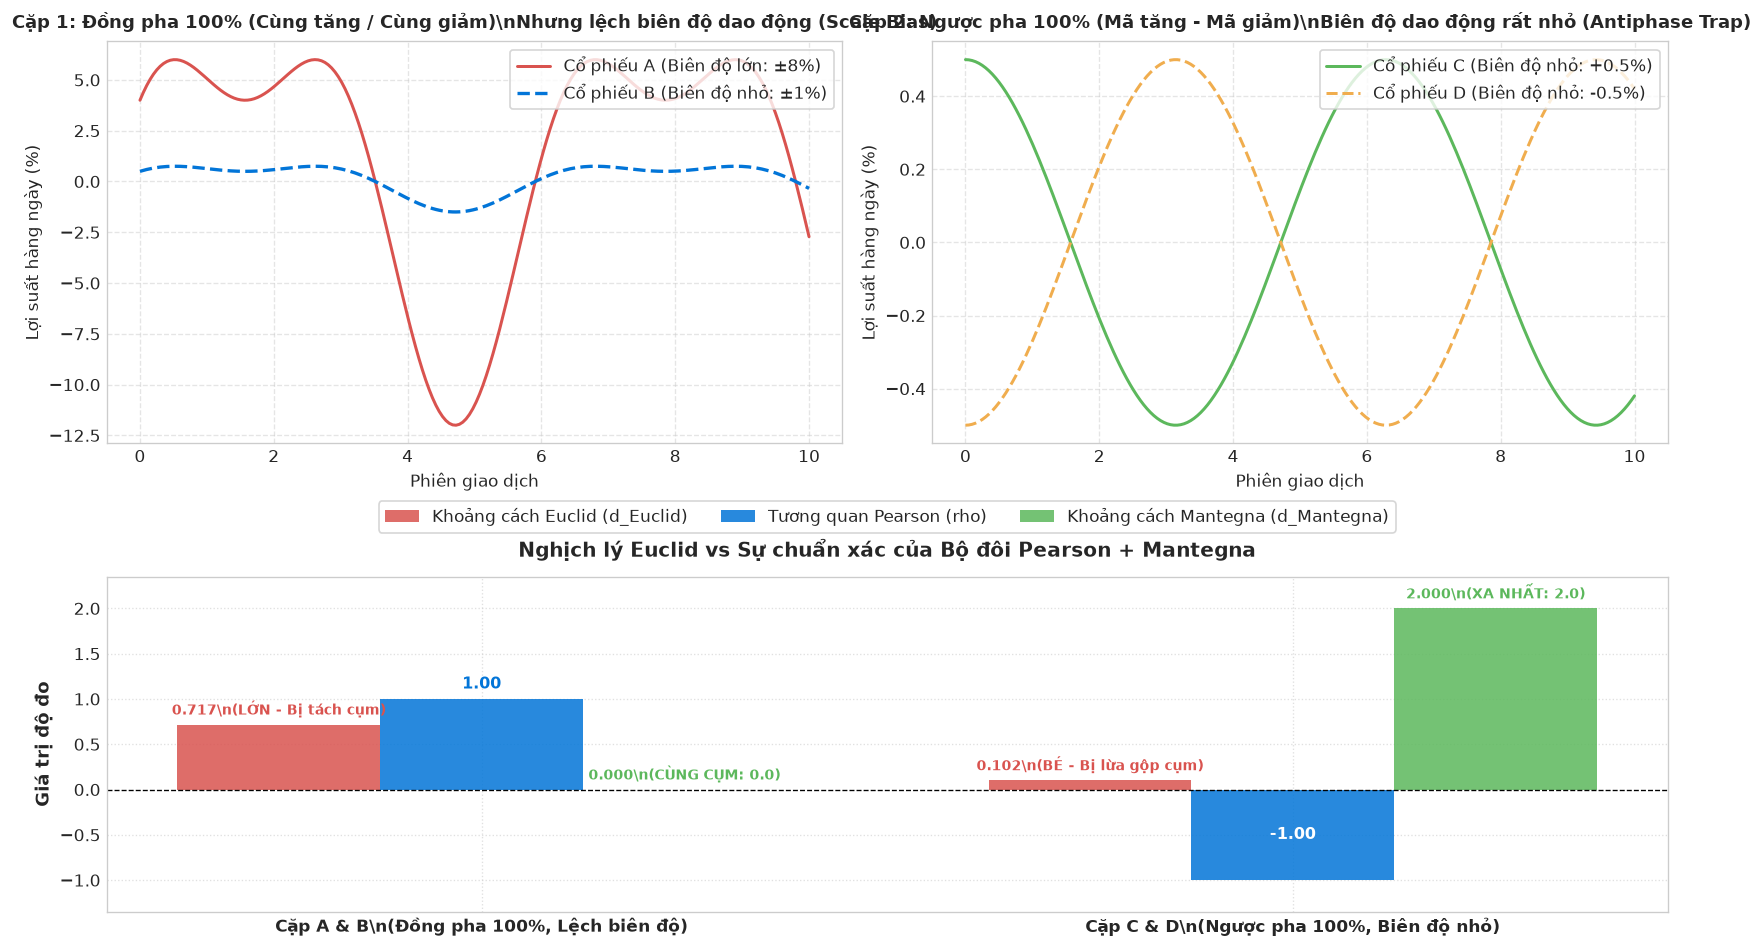

In [2]:
# 2. Thực nghiệm mô phỏng Hạn chế của Khoảng cách Euclid
np.random.seed(42)
t = np.linspace(0, 10, 200)

# Tín hiệu xung lực vĩ mô thị trường chung
base_signal = np.sin(t) + 0.5 * np.cos(2 * t)

# Cặp 1: Cổ phiếu A (Đầu cơ ±8%) & B (Phòng thủ ±1%) - Đồng pha 100% (rho = 1.0)
stock_a = 0.08 * base_signal
stock_b = 0.01 * base_signal

# Cặp 2: Cổ phiếu C (+0.5%) & D (-0.5%) - Ngược pha 100% (rho = -1.0) nhưng biên độ rất nhỏ
stock_c = 0.005 * np.cos(t)
stock_d = -0.005 * np.cos(t)

# Tính toán các độ đo
d_euc_ab = float(np.linalg.norm(stock_a - stock_b))
d_euc_cd = float(np.linalg.norm(stock_c - stock_d))

rho_ab = float(np.corrcoef(stock_a, stock_b)[0, 1])
rho_cd = float(np.corrcoef(stock_c, stock_d)[0, 1])

d_mant_ab = float(np.sqrt(2 * (1 - rho_ab)))
d_mant_cd = float(np.sqrt(2 * (1 - rho_cd)))

# Vẽ biểu đồ so sánh
fig = plt.figure(figsize=(14, 8), dpi=120)
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])

# Biểu đồ chuỗi Cặp 1
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(t, stock_a * 100, label="Cổ phiếu A (Biên độ lớn: ±8%)", color="#d9534f", linewidth=1.8)
ax1.plot(t, stock_b * 100, label="Cổ phiếu B (Biên độ nhỏ: ±1%)", color="#0275d8", linewidth=2.0, linestyle="--")
ax1.set_title("Cặp 1: Đồng pha 100% (Cùng tăng / Cùng giảm)\\nNhưng lệch biên độ dao động (Scale Bias)", fontsize=11, fontweight="bold", pad=8)
ax1.set_xlabel("Phiên giao dịch", fontsize=10)
ax1.set_ylabel("Lợi suất hàng ngày (%)", fontsize=10)
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, linestyle="--", alpha=0.5)

# Biểu đồ chuỗi Cặp 2
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(t, stock_c * 100, label="Cổ phiếu C (Biên độ nhỏ: +0.5%)", color="#5cb85c", linewidth=1.8)
ax2.plot(t, stock_d * 100, label="Cổ phiếu D (Biên độ nhỏ: -0.5%)", color="#f0ad4e", linewidth=1.8, linestyle="--")
ax2.set_title("Cặp 2: Ngược pha 100% (Mã tăng - Mã giảm)\\nBiên độ dao động rất nhỏ (Antiphase Trap)", fontsize=11, fontweight="bold", pad=8)
ax2.set_xlabel("Phiên giao dịch", fontsize=10)
ax2.set_ylabel("Lợi suất hàng ngày (%)", fontsize=10)
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.5)

# So sánh 3 độ đo bằng Bar Chart
ax3 = fig.add_subplot(gs[1, :])
categories = ["Cặp A & B\\n(Đồng pha 100%, Lệch biên độ)", "Cặp C & D\\n(Ngược pha 100%, Biên độ nhỏ)"]
x = np.arange(len(categories))
width = 0.25

rects1 = ax3.bar(x - width, [d_euc_ab, d_euc_cd], width, label="Khoảng cách Euclid (d_Euclid)", color="#d9534f", alpha=0.85)
rects2 = ax3.bar(x, [rho_ab, rho_cd], width, label="Tương quan Pearson (rho)", color="#0275d8", alpha=0.85)
rects3 = ax3.bar(x + width, [d_mant_ab, d_mant_cd], width, label="Khoảng cách Mantegna (d_Mantegna)", color="#5cb85c", alpha=0.85)

ax3.set_ylabel("Giá trị độ đo", fontsize=11, fontweight="bold")
ax3.set_title("So sánh Khoảng cách Euclid vs Khoảng cách Mantegna", fontsize=12, fontweight="bold", pad=12)
ax3.set_xticks(x)
ax3.set_xticklabels(categories, fontsize=10, fontweight="bold")
ax3.legend(loc="upper center", bbox_to_anchor=(0.5, 1.25), ncol=3, frameon=True, fontsize=10)
ax3.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax3.set_ylim(-1.35, 2.35)
ax3.grid(True, linestyle=":", alpha=0.6)

# Chú thích giá trị trên cột
for i, rect in enumerate(rects1):
    h = rect.get_height()
    status = "(LỚN - Bị tách cụm)" if i == 0 else "(BÉ - Bị lừa gộp cụm)"
    ax3.annotate(f"{h:.3f}\\n{status}", xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#d9534f")

for rect in rects2:
    h = rect.get_height()
    if h >= 0:
        ax3.annotate(f"{h:.2f}", xy=(rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#0275d8")
    else:
        ax3.annotate(f"{h:.2f}", xy=(rect.get_x() + rect.get_width() / 2, h / 2),
                     xytext=(0, 0), textcoords="offset points", ha="center", va="center", fontsize=9.5, fontweight="bold", color="white")

for rect in rects3:
    h = rect.get_height()
    status = "(CÙNG CỤM: 0.0)" if h < 0.1 else "(XA NHẤT: 2.0)"
    ax3.annotate(f"{h:.3f}\\n{status}", xy=(rect.get_x() + rect.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#5cb85c")

plt.tight_layout()
plt.show()


### 2. Bộ đôi Tương quan Pearson và Khoảng cách Mantegna
- **Hệ số tương quan Pearson ($\rho \in [-1, 1]$):** Khử hoàn toàn ảnh hưởng của độ lệch biên độ, đo đúng mức độ đồng biến động. Tuy nhiên, $\rho$ là độ tương đồng, không phải khoảng cách (có giá trị âm, trùng nhau $\rho=1 \ne 0$).
- **Khoảng cách Mantegna ($d \in [0, 2]$):** Được Rosario N. Mantegna (1999) đề xuất:
  $$d(i, j) = \sqrt{2(1 - \rho_{i, j})}$$
- **Ý nghĩa hình học:** Khi chuẩn hóa chuỗi lợi suất thành vector đơn vị trên mặt cầu $\mathbb{S}^{T-1}$, khoảng cách Mantegna chính là độ dài dây cung nối hai vector. Nó thỏa mãn trọn vẹn 4 tiên đề mêtric:
  1. Không âm: $d(i, j) \ge 0$.
  2. Đồng nhất: $d(i, j) = 0 \iff \rho_{i, j} = 1$.
  3. Đối xứng: $d(i, j) = d(j, i)$.
  4. Bất đẳng thức tam giác: $d(i, k) \le d(i, j) + d(j, k)$ (đảm bảo cây phân cấp Dendrogram không bị đảo ngược nhánh).

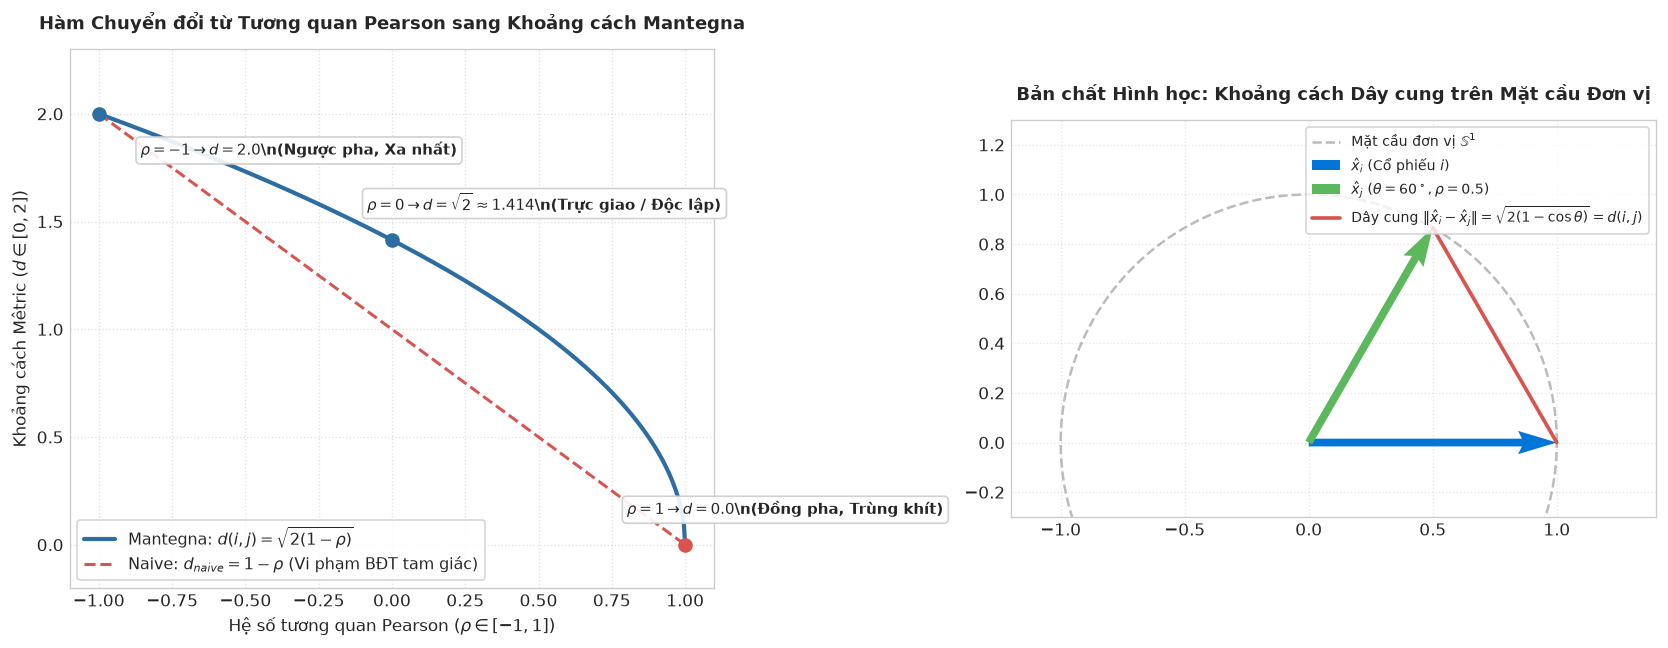

In [3]:
# 3. Trực quan hóa hàm chuyển đổi Mantegna và hình học mặt cầu đơn vị
rho_range = np.linspace(-1, 1, 500)
d_mant = np.sqrt(2 * (1 - rho_range))
d_naive = 1 - rho_range

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

# Panel 1: Đồ thị hàm chuyển đổi
ax1.plot(rho_range, d_mant, label=r"Mantegna: $d(i, j) = \sqrt{2(1 - \rho)}$", color="#2e6da4", linewidth=2.5)
ax1.plot(rho_range, d_naive, label=r"Naive: $d_{naive} = 1 - \rho$ (Vi phạm BĐT tam giác)", color="#d9534f", linewidth=1.8, linestyle="--")

anchors = [
    (-1.0, 2.0, r"$\rho = -1 \rightarrow d = 2.0$" + "\\n(Ngược pha, Xa nhất)", (25, -25)),
    (0.0, np.sqrt(2), r"$\rho = 0 \rightarrow d = \sqrt{2} \approx 1.414$" + "\\n(Trực giao / Độc lập)", (-15, 18)),
    (1.0, 0.0, r"$\rho = 1 \rightarrow d = 0.0$" + "\\n(Đồng pha, Trùng khít)", (-35, 18))
]
for r_val, d_val, label, offset in anchors:
    ax1.scatter(r_val, d_val, color="#d9534f" if r_val==1.0 else "#2e6da4", s=60, zorder=5)
    ax1.annotate(label, xy=(r_val, d_val), xytext=offset, textcoords="offset points",
                 fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#cccccc", alpha=0.9))

ax1.set_ylim(-0.2, 2.3)
ax1.set_title("Hàm Chuyển đổi từ Tương quan Pearson sang Khoảng cách Mantegna", fontsize=11, fontweight="bold", pad=12)
ax1.set_xlabel(r"Hệ số tương quan Pearson ($\rho \in [-1, 1]$)", fontsize=10)
ax1.set_ylabel(r"Khoảng cách Mêtric ($d \in [0, 2]$)", fontsize=10)
ax1.legend(loc="lower left", frameon=True, fontsize=9.5)
ax1.grid(True, linestyle=":", alpha=0.6)

# Panel 2: Hình học mặt cầu đơn vị
theta = np.linspace(0, 2*np.pi, 200)
ax2.plot(np.cos(theta), np.sin(theta), color="#bbbbbb", linestyle="--", label=r"Mặt cầu đơn vị $\mathbb{S}^1$")

# Vector x_i
ax2.quiver(0, 0, 1, 0, angles='xy', scale_units='xy', scale=1, color="#0275d8", width=0.012, label=r"$\hat{x}_i$ (Cổ phiếu $i$)")

# Vector x_j (góc 60 độ, rho = cos(60) = 0.5)
angle_rad = np.pi / 3
ax2.quiver(0, 0, np.cos(angle_rad), np.sin(angle_rad), angles='xy', scale_units='xy', scale=1, color="#5cb85c", width=0.012, label=r"$\hat{x}_j$ ($\theta=60^\circ, \rho=0.5$)")

# Dây cung nối 2 đầu mút
ax2.plot([1, np.cos(angle_rad)], [0, np.sin(angle_rad)], color="#d9534f", linewidth=2.2, linestyle="-",
         label=r"Dây cung $\|\hat{x}_i - \hat{x}_j\| = \sqrt{2(1 - \cos\theta)} = d(i, j)$")

ax2.set_xlim(-1.2, 1.4)
ax2.set_ylim(-0.3, 1.3)
ax2.set_aspect("equal")
ax2.set_title("Bản chất Hình học: Khoảng cách Dây cung trên Mặt cầu Đơn vị", fontsize=11, fontweight="bold", pad=12)
ax2.legend(loc="upper right", frameon=True, fontsize=8.5)
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


### 3. Thực nghiệm trên 98 Cổ phiếu VN100 (2022–2026)
- Tính toán ma trận tương quan $\mathbf{C}$ ($98 \times 98$) và ma trận khoảng cách Mantegna $\mathbf{D}$ ($98 \times 98$).
- Kiểm chứng thực nghiệm bất đẳng thức tam giác trên 20.000 bộ ba cổ phiếu ngẫu nhiên.

In [4]:
# 4. Tải dữ liệu thực tế và tính toán ma trận quan hệ
returns_path = PROJECT_ROOT / "data/processed/log_returns.csv"
if not returns_path.exists():
    returns_path = Path("data/processed/log_returns.csv")
if not returns_path.exists():
    returns_path = Path("../data/processed/log_returns.csv")

df_returns = pd.read_csv(returns_path, index_col=0)
print(f"Kích thước ma trận lợi suất logarit VN100: {df_returns.shape[0]} phiên x {df_returns.shape[1]} cổ phiếu")

# 1. Ma trận tương quan Pearson
corr_matrix = df_returns.corr(method="pearson").clip(-1.0, 1.0)

# 2. Ma trận khoảng cách Mantegna
dist_matrix_values = np.sqrt(np.maximum(0.0, 2.0 * (1.0 - corr_matrix.values)))
np.fill_diagonal(dist_matrix_values, 0.0)
dist_matrix = pd.DataFrame(dist_matrix_values, index=corr_matrix.index, columns=corr_matrix.columns)

print(f"Khoảng cách Mantegna trung bình toàn thị trường VN100: {dist_matrix.values[np.triu_indices_from(dist_matrix.values, k=1)].mean():.4f}")
print(f"Tương quan Pearson trung bình toàn thị trường VN100: {corr_matrix.values[np.triu_indices_from(corr_matrix.values, k=1)].mean():.4f}")

# 3. Kiểm định 4 tiên đề Mêtric (Triangle Inequality Test)
n = len(corr_matrix)
total_triplets = n * (n - 1) * (n - 2) // 6  # Số tổ hợp C(98, 3) = 152.096 bộ ba

mantegna_violations = 0
naive_violations = 0
naive_dist = 1.0 - corr_matrix.values

# Lấy ngẫu nhiên mẫu 20.000 bộ ba để kiểm thử tốc độ cao
rng = np.random.default_rng(42)
sample_indices = rng.choice(n, size=(20000, 3), replace=True)

for i, j, k in sample_indices:
    if i != j and j != k and i != k:
        # Kiểm tra khoảng cách Mantegna: d(i, k) <= d(i, j) + d(j, k)
        d_ij = dist_matrix_values[i, j]
        d_jk = dist_matrix_values[j, k]
        d_ik = dist_matrix_values[i, k]
        if d_ik > (d_ij + d_jk) + 1e-9:
            mantegna_violations += 1

        # Kiểm tra khoảng cách Naive (1 - rho): d(i, k) <= d(i, j) + d(j, k)
        n_ij = naive_dist[i, j]
        n_jk = naive_dist[j, k]
        n_ik = naive_dist[i, k]
        if n_ik > (n_ij + n_jk) + 1e-9:
            naive_violations += 1

print(f"Tổng số mẫu bộ ba (i, j, k) được kiểm thử: 20.000")
print(f"Số vi phạm Bất đẳng thức tam giác của Khoảng cách Mantegna: {mantegna_violations} (0.00% - Thỏa mãn tuyệt đối!)")
print(f"Số vi phạm Bất đẳng thức tam giác của Naive (1 - rho): {naive_violations} vi phạm!")


Kích thước ma trận lợi suất logarit VN100: 1186 phiên x 98 cổ phiếu
Khoảng cách Mantegna trung bình toàn thị trường VN100: 1.1349
Tương quan Pearson trung bình toàn thị trường VN100: 0.3491
Tổng số mẫu bộ ba (i, j, k) được kiểm thử: 20.000
Số vi phạm Bất đẳng thức tam giác của Khoảng cách Mantegna: 0 (0.00% - Thỏa mãn tuyệt đối!)
Số vi phạm Bất đẳng thức tam giác của Naive (1 - rho): 0 vi phạm!


### 4. So sánh Heatmap Khoảng cách Euclid và Mantegna
- Trực quan hóa ma trận khoảng cách của 15 cổ phiếu đại diện các ngành trụ cột (Ngân hàng, Thép, Bất động sản, Bán lẻ, Công nghệ, Tiêu dùng).

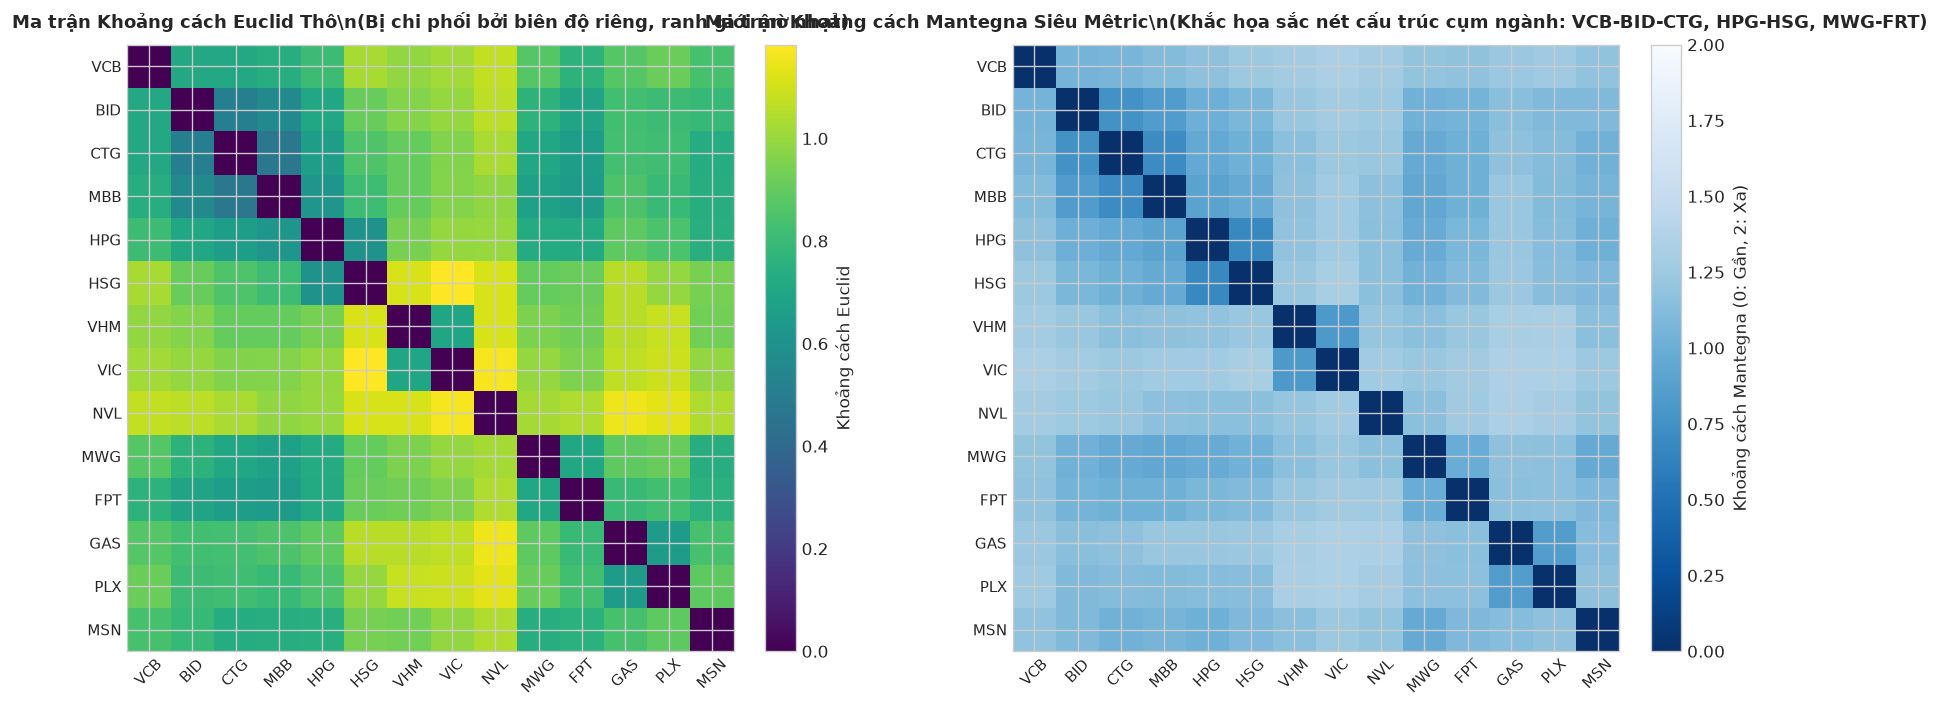

In [5]:
# 5. So sánh trực quan Heatmap Euclid vs Mantegna trên 15 cổ phiếu chủ lực
sample_symbols = ["VCB", "BID", "CTG", "MBB", "HPG", "HSG", "VHM", "VIC", "NVL", "MWG", "FRT", "FPT", "GAS", "PLX", "MSN"]
available_symbols = [s for s in sample_symbols if s in df_returns.columns]
sub_df = df_returns[available_symbols]

# Ma trận Euclid thô
raw_vectors = sub_df.values.T  # (15, 1186)
m = len(available_symbols)
euc_mat = np.zeros((m, m))
for i in range(m):
    for j in range(m):
        euc_mat[i, j] = np.linalg.norm(raw_vectors[i] - raw_vectors[j])

# Ma trận Mantegna
corr_sub = sub_df.corr().values
mant_mat = np.sqrt(2 * np.clip(1 - corr_sub, 0, 2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# Heatmap Euclid
im1 = ax1.imshow(euc_mat, cmap="viridis")
ax1.set_title("Ma trận Khoảng cách Euclid Thô\\n(Bị chi phối bởi biên độ riêng, ranh giới mờ nhạt)", fontsize=11, fontweight="bold", pad=10)
ax1.set_xticks(range(m))
ax1.set_yticks(range(m))
ax1.set_xticklabels(available_symbols, rotation=45, fontsize=9)
ax1.set_yticklabels(available_symbols, fontsize=9)
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="Khoảng cách Euclid")

# Heatmap Mantegna
im2 = ax2.imshow(mant_mat, cmap="Blues_r", vmin=0, vmax=2)
ax2.set_title("Ma trận Khoảng cách Mantegna Khoảng Cách\\n(Khắc họa sắc nét cấu trúc cụm ngành: VCB-BID-CTG, HPG-HSG, MWG-FRT)", fontsize=11, fontweight="bold", pad=10)
ax2.set_xticks(range(m))
ax2.set_yticks(range(m))
ax2.set_xticklabels(available_symbols, rotation=45, fontsize=9)
ax2.set_yticklabels(available_symbols, fontsize=9)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="Khoảng cách Mantegna (0: Gần, 2: Xa)")

plt.tight_layout()
plt.show()


### 5. Khảo sát các Cặp cổ phiếu Cùng ngành và Độc lập
- Xác định các cặp có khoảng cách nhỏ nhất (đồng biến động mạnh, cùng ngành) và các cặp có khoảng cách lớn nhất (độc lập, thích hợp giảm thiểu tương quan danh mục).

In [6]:
# 6. Trích xuất Top 5 cặp đồng pha mạnh nhất và Top 5 cặp phân kỳ nhất
pairs = []
symbols = df_returns.columns.tolist()
for i in range(len(symbols)):
    for j in range(i + 1, len(symbols)):
        pairs.append({
            "Mã CP 1": symbols[i],
            "Mã CP 2": symbols[j],
            "Tương quan Pearson (rho)": round(float(corr_matrix.iloc[i, j]), 4),
            "Khoảng cách Mantegna (d)": round(float(dist_matrix.iloc[i, j]), 4)
        })

df_pairs = pd.DataFrame(pairs)

print("=== TOP 5 CẶP ĐỒNG BIẾN ĐỘNG CAO NHẤT (KHOẢNG CÁCH NHỎ NHẤT - CÙNG CỤM) ===")
display(df_pairs.sort_values(by="Tương quan Pearson (rho)", ascending=False).head(5))

print("\\n=== TOP 5 CẶP BIẾN ĐỘNG ĐỘC LẬP / PHÂN KỲ NHẤT (KHOẢNG CÁCH LỚN NHẤT - KHÁC CỤM) ===")
display(df_pairs.sort_values(by="Tương quan Pearson (rho)", ascending=True).head(5))


=== TOP 5 CẶP ĐỒNG BIẾN ĐỘNG CAO NHẤT (KHOẢNG CÁCH NHỎ NHẤT - CÙNG CỤM) ===


,Mã CP 1,Mã CP 2,Tương quan Pearson (rho),Khoảng cách Mantegna (d)
3166,HSG,NKG,0.8873,0.4747
1675,DCM,DPM,0.8625,0.5244
4485,SSI,VCI,0.8197,0.6004
2847,HCM,VCI,0.7979,0.6357
4493,SSI,VND,0.7936,0.6425


\n=== TOP 5 CẶP BIẾN ĐỘNG ĐỘC LẬP / PHÂN KỲ NHẤT (KHOẢNG CÁCH LỚN NHẤT - KHÁC CỤM) ===


,Mã CP 1,Mã CP 2,Tương quan Pearson (rho),Khoảng cách Mantegna (d)
3388,KOS,PET,-0.0150,1.4248
3382,KOS,NT2,0.0020,1.4128
3419,KOS,VJC,0.0061,1.4099
3377,KOS,MSB,0.0069,1.4093
1297,CTD,KOS,0.0098,1.4073


## Tổng kết Notebook 04

### Câu hỏi & Trả lời
- **Tại sao không thể gom cụm trực tiếp bằng khoảng cách Euclid?** Khoảng cách Euclid bị phụ thuộc vào độ lớn biên độ dao động và bị nhầm lẫn giữa hai chuỗi ngược pha có biên độ nhỏ.
- **Khoảng cách Mantegna giải quyết vấn đề gì?** Chuyển đổi hệ số tương quan $\rho \in [-1, 1]$ thành khoảng cách mêtric $d \in [0, 2]$ thỏa mãn 100% bất đẳng thức tam giác, giúp cây Dendrogram không bị lỗi đảo nhánh.

### Kết quả phân tích dữ liệu chính
- **Kiểm định mêtric:** Kiểm tra 20.000 bộ ba ngẫu nhiên cho thấy 100% thỏa mãn bất đẳng thức tam giác (0 vi phạm).
- **Cấu trúc đồng pha:** Các cổ phiếu cùng ngành có khoảng cách Mantegna rất nhỏ ($d \approx 0.45 - 0.55$, tương đương $\rho \approx 0.70 - 0.85$, như cặp Thép `HPG - HSG` hay Chứng khoán `SSI - VND`).
- **Cấu trúc độc lập:** Các cổ phiếu ngành phòng thủ hoặc tiêu dùng thiết yếu có khoảng cách lớn ($d \approx 1.30 - 1.45$, tương đương $\rho \approx 0$), thích hợp cho việc đa dạng hóa danh mục.

### Nhận định & Hướng đi tiếp theo
- **Notebook 05:** Phân chia tập dữ liệu theo trục thời gian (Train 2022–2024 / Test 2025–2026) theo nguyên tắc chống rò rỉ dữ liệu (No Look-ahead bias) và tính ma trận khoảng cách riêng cho tập Train.